In [1]:
from datasets import load_from_disk

/nfs/team361/sb75/ENVS/rapids-singlecell-nichejepa/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [4]:
ds = load_from_disk('/nfs/team361/sb75/nichejepa-reproducibility/artifacts/hst_corpus_110m/07112025_054432_709/5k.dataset')

In [5]:
ds

Dataset({
    features: ['rel_x_coord', 'rel_y_coord', 'cell_id', 'batch_value', 'gene_panel_value', 'assay_value', 'species_value', 'tissue_value', 'gene_tokens', 'gene_expr', 'n_nonzero_tokens', 'batch_token', 'gene_panel_token', 'assay_token', 'species_token', 'tissue_token'],
    num_rows: 40712678
})

In [6]:
test_ds = ds.select(range(100000))

In [9]:
chunk_size = 1000000

chunks = []

for start in range(0, len(ds), chunk_size):
    end = min(start + chunk_size, len(ds))
    indices = list(range(start, end))
    chunk = ds.select(indices)
    chunks.append(chunk)

In [11]:
chunks[-1]

Dataset({
    features: ['rel_x_coord', 'rel_y_coord', 'cell_id', 'batch_value', 'gene_panel_value', 'assay_value', 'species_value', 'tissue_value', 'gene_tokens', 'gene_expr', 'n_nonzero_tokens', 'batch_token', 'gene_panel_token', 'assay_token', 'species_token', 'tissue_token'],
    num_rows: 712678
})

In [ ]:
chunks

In [ ]:
tissue_val = list(ds['tissue_value'])

In [ ]:
set(tissue_val)

In [2]:
dataset = load_from_disk(f'/lustre/scratch126/cellgen/lotfollahi/DATASETS/gold/cell-graph-tokenizer/mmb0-1b_smb1-1b_1p/mmb0-1b_smb1-1b_1p_32_None_None_None_None_None_shifted_log_knn_10_704.dataset')

In [3]:
item = dataset[0]

In [ ]:
item

In [ ]:
from datasets import Dataset, Features, Array2D, Value
import numpy as np

L = len(dataset[0]["gene_tokens"])

features = Features({
    "gene_tokens": Array2D(dtype="int64", shape=(L,1)),
    "gene_expr":   Array2D(dtype="float32", shape=(L,1)),
    #"batch_token": Array2D(dtype="float32", shape=(L,1)),
    #"batch_value": Array2D(dtype="float32", shape=(L,1)),
    #"n_nonzero_tokens": Value("int64"),
})

new_ds = Dataset.from_dict(
    {
        "gene_tokens": np.array(gene_tokens),
        "gene_expr": np.array(gene_expr),
        #"batch_token": np.array(batch_token),
        #"batch_value": np.array(batch_value),
        #"n_nonzero_tokens": np.array(n_nonzero_tokens),
    },
    features=features
)

ds = ds.with_format("torch")

In [ ]:
np.array(gene_tokens)

In [ ]:
# Format dataset
exclude_cols = [
    'rel_x_coord',
    'rel_y_coord',
    'gene_panel_value',
    'assay_value',
    'species_value',
    'tissue_value']
cols = [
    c for c in dataset.column_names if c not in exclude_cols and (
        c != 'cell_id' or include_cell_id)]
ds = dataset.with_format(
    type="torch", columns=cols, output_all_columns=False)

In [ ]:
from datasets import Features, Array2D, Array1D, Value

In [ ]:
ds['gene_expr']

In [ ]:
from datasets import Dataset
data = [[1, 2], [3, 4]]
ds = Dataset.from_dict({"data": data})
ds = ds.with_format("numpy")
ds[0]

In [ ]:
ds.features

In [ ]:
ds[0]

In [ ]:
ds.format

In [ ]:
item = ds[0]
item

In [ ]:
dataset.features

In [ ]:
exclude_cols = [
    'rel_x_coord',
    'rel_y_coord',
    'gene_panel_value',
    'assay_value',
    'species_value',
    'tissue_value',]
if not include_cell_id:
    exclude_cols += ['cell_id']
dataset = dataset.remove_columns(exclude_cols)

In [ ]:
L = len(dataset[0]["gene_tokens"])

def to_fixed_arrays(example):
    example["gene_tokens"] = example["gene_tokens"][:L]
    example["gene_expr"]   = example["gene_expr"][:L]
    example["batch_token"] = example["batch_token"][0]
    example["batch_value"] = example["batch_value"][0]
    return example

dataset_fixed = dataset.map(
    to_fixed_arrays,
    num_proc=8,
    desc="Rewriting list columns to fixed arrays"
)

In [ ]:
import numpy as np

L = len(dataset[0]["gene_tokens"])

def to_numpy(example):
    example["gene_tokens"] = np.array(example["gene_tokens"], dtype=np.int64)
    example["gene_expr"]   = np.array(example["gene_expr"], dtype=np.float32)
    example["batch_token"] = np.array(example["batch_token"], dtype=np.int64)
    example["batch_value"] = np.array(example["batch_value"], dtype=np.int64)
    return example

dataset_np = dataset.map(
    to_numpy,
    num_proc=8,
    load_from_cache_file=False,
    desc="Rewriting lists as numpy arrays"
)

In [ ]:
item = dataset[0]

In [ ]:
len(item['gene_tokens'])

In [ ]:
import numpy as np
from datasets import Dataset

# Determine fixed size
L = len(dataset[0]["gene_tokens"])

gene_tokens = []
gene_expr = []
batch_token = []
batch_value = []
n_nonzero_tokens = []

for ex in dataset:
    gene_tokens.append(np.array(ex["gene_tokens"], dtype=np.int64))
    gene_expr.append(np.array(ex["gene_expr"], dtype=np.float32))
    batch_token.append(ex["batch_token"])
    batch_value.append(ex["batch_value"])
    n_nonzero_tokens.append(ex["n_nonzero_tokens"])

In [ ]:
import numpy as np
from datasets import Dataset, Features, Array2D

features = Features({
    "gene_tokens": Array2D(dtype="int64", shape=(3,1)),
})

new_dataset = Dataset.from_dict(
    {
        "gene_tokens": [
            np.array([2, 3, 4], dtype=np.int64),
            np.array([1, 2, 3], dtype=np.int64),
        ]
    },
    features=features
)

print(new_dataset.features)
print(new_dataset.data.schema)


##### new_dataset = Dataset.from_dict({
    "gene_tokens": np.array(gene_tokens),
    "gene_expr": np.array(gene_expr),
    "batch_token": np.array(batch_token),
    "batch_value": np.array(batch_value),
    "n_nonzero_tokens": np.array(n_nonzero_tokens),
})

In [ ]:
new_dataset = Dataset.from_dict({
    "gene_tokens": np.array([np.array([2,3,4]), np.array([1,2,3])])
})

In [ ]:
new_dataset.features

In [ ]:
new_dataset['gene_tokens']

In [ ]:
exclude_cols = ['rel_x_coord', 'rel_y_coord', 'gene_panel_value', 'assay_value', 'species_value', 'tissue_value']
cols = [
    c for c in dataset.column_names if c not in exclude_cols and (c != 'cell_id' or include_cell_id)]
dataset.set_format(
    type="torch", columns=cols, output_all_columns=False)

In [ ]:
print(new_dataset.features)

In [ ]:
import pyarrow as pa

table = new_dataset.data  # <-- underlying Arrow table
schema = table.schema
print(schema)

In [ ]:
from datasets import Dataset, Features, Array2D, Value
import numpy as np

L = len(dataset[0]["gene_tokens"])

features = Features({
    "gene_tokens": Array2D(dtype="int64", shape=(L,1)),
    "gene_expr":   Array2D(dtype="float32", shape=(L,1)),
    #"batch_token": Array2D(dtype="float32", shape=(L,1)),
    #"batch_value": Array2D(dtype="float32", shape=(L,1)),
    #"n_nonzero_tokens": Value("int64"),
})

new_ds = Dataset.from_dict(
    {
        "gene_tokens": np.array(gene_tokens),
        "gene_expr": np.array(gene_expr),
        #"batch_token": np.array(batch_token),
        #"batch_value": np.array(batch_value),
        #"n_nonzero_tokens": np.array(n_nonzero_tokens),
    },
    features=features       # <--- SUPER IMPORTANT
)

In [ ]:
new_ds.features

In [ ]:
arr = table.column("gene_tokens")
print(type(arr))
print(arr)

In [ ]:
dataset

In [ ]:
item

In [ ]:
item['gene_tokens']

In [ ]:
item = dataset[0]
item

In [ ]:
dataset['rel_x_coord']

In [ ]:
dataset['rel_y_coord']

In [ ]:
dataset['gene_panel_value']

In [ ]:
dataset

In [ ]:
item = dataset[0]

In [ ]:
item-=

In [ ]:
import math
distances = [math.sqrt(dx**2 + dy**2) for dx, dy in zip(list(item['rel_x_coord']), list(item['rel_y_coord']))]
print(distances)

In [ ]:
sample_size = 0.5

In [ ]:
#dataset = load_from_disk(f'/nfs/team361/sb75/DATASETS/gold/cell-graph-tokenizer/hst_corpus_110m/hst_corpus_110m_{sample_size}_sample_32_None_None_None_None_None_shifted_log_knn_10.dataset')
#dataset = load_from_disk(f'/lustre/scratch126/cellgen/lotfollahi/DATASETS/gold/cell-graph-tokenizer/hst_corpus_110m/hst_corpus_110m_32_None_None_None_None_None_shifted_log_knn_6.dataset')
dataset = load_from_disk(f'/lustre/scratch126/cellgen/lotfollahi/DATASETS/gold/cell-graph-tokenizer/xhs1000-39b_1p/xhs1000-39b_1p_32_None_None_None_None_None_shifted_log_knn_10_2816.dataset')

In [ ]:
item = dataset[0]

In [ ]:
item

In [ ]:
len(item['gene_tokens'])

In [ ]:
import pickle

#split_path = f'/nfs/team361/sb75/DATASETS/tokenizer/hst_corpus_110m_{sample_size}_sample_32_None_None_None_None_None_shifted_log_knn_10_precomputed_split_full.pkl'
split_path = f'/nfs/team361/sb75/DATASETS/tokenizer/hst_corpus_110m_32_None_None_None_None_None_shifted_log_knn_6_precomputed_split_train.pkl'

with open(split_path, 'rb') as f:
    split = pickle.load(f)

print(split[:100])
print(split[-100:])
print(len(split))

In [ ]:
import pickle

#nz_tokens_path = f'/nfs/team361/sb75/DATASETS/tokenizer/hst_corpus_110m_{sample_size}_sample_32_None_None_None_None_None_shifted_log_knn_10_n_nonzero_tokens_full.pkl'
nz_tokens_path = f'/nfs/team361/sb75/DATASETS/tokenizer/hst_corpus_110m_32_None_None_None_None_None_shifted_log_knn_6_n_nonzero_tokens_train.pkl'

with open(nz_tokens_path, 'rb') as f:
    nz_tokens = pickle.load(f)

print(nz_tokens[:100])
print(nz_tokens[-100:])

In [ ]:
train_dataset = dataset.select(split)

ds_nz_tokens = train_dataset['n_nonzero_tokens']

print(ds_nz_tokens[:100])
print(ds_nz_tokens[-100:])

In [ ]:
import pickle

idx_path = '/lustre/scratch126/cellgen/lotfollahi/DATASETS/tokenizer/hst_corpus_110m_32_None_None_None_None_None_shifted_log_knn_10_precomputed_loader_idx_split_train.pkl'

with open(idx_path, 'rb') as f:
    idx = pickle.load(f)

In [ ]:
len(idx)

In [ ]:
from datasets import load_from_disk

In [ ]:
ds = load_from_disk('/lustre/scratch126/cellgen/lotfollahi/DATASETS/gold/cell-graph-tokenizer/hst_corpus_110m/hst_corpus_110m_32_None_None_None_None_None_shifted_log_knn_10_ordered_full.dataset')

In [ ]:
ds

In [ ]:
from pathlib import Path

root = Path("/lustre/scratch126/cellgen/lotfollahi/DATASETS/gold/cell-graph-tokenizer")
pattern = "None_None_None_None_None_shifted_log_knn_6_7168.dataset"

# Recursively search for directories containing the pattern in their name
matching_dirs = [
    str(p) for p in root.rglob("*")
    if p.is_dir() and pattern in p.name
]

print(f"Found {len(matching_dirs)} matching directories:")
for d in matching_dirs:
    #if d == '/lustre/scratch126/cellgen/lotfollahi/DATASETS/gold/cell-graph-tokenizer/xhb1002-AT12-1b_1p/xhb1002-AT12-1b_1p_32_None_None_None_None_None_shifted_log_knn_6_7168.dataset':
    #    continue
    #elif d == '/lustre/scratch126/cellgen/lotfollahi/DATASETS/gold/cell-graph-tokenizer/xhl1015-R6-28b_1p/xhl1015-R6-28b_1p_32_None_None_None_None_None_shifted_log_knn_6_7168.dataset':
    #    continue
    #elif d == '/lustre/scratch126/cellgen/lotfollahi/DATASETS/gold/cell-graph-tokenizer/xho1012-Hrv162-2b_1p/xho1012-Hrv162-2b_1p_32_None_None_None_None_None_shifted_log_knn_6_7168.dataset':
    #    continue
    #else:
    ds = load_from_disk(d)
    if 'batch_token' not in ds.features.keys():
        print(d)
        print(ds)
        print('===')

In [ ]:
/lustre/scratch126/cellgen/lotfollahi/DATASETS/gold/cell-graph-tokenizer/xhb1002-AT12-1b_1p/xhb1002-AT12-1b_1p_32_None_None_None_None_None_shifted_log_knn_6_7168.dataset

In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import pickle
import time
import timeit
import random

import torch
from datasets import load_from_disk

from nichejepa.masks_new.block_masking  import BlockMaskCollator
from nichejepa.datasets_new.cell_datasets import init_cell_dataset
from nichejepa.datasets_new.dataloaders import init_dataloader_and_sampler, CustomDistributedLengthGroupedSampler

/nfs/users/nfs_s/sb75/.venvs/nichejepa/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
/nfs/users/nfs_s/sb75/.venvs/nichejepa/lib/python3.10/site-packages/dask/dataframe/__init__.py:31: FutureWarning: The legacy Dask DataFrame implementation is deprecated and will be removed in a future version. Set the configuration option `dataframe.query-planning` to `True` or None to enable the new Dask Dataframe implementation and silence this warning.
  warnings.warn(
/nfs/users/nfs_s/sb75/.venvs/nichejepa/lib/python3.10/site-packages/anndata/utils.py:434: FutureWarning: Importing read_text from `anndata` is deprecated. Import anndata.io.read_text instead.
  warnings.warn(msg, FutureWarning)


In [3]:
batch_size = 124

In [4]:
# Load Huggingface Dataset
#data_path = '/lustre/scratch126/cellgen/lotfollahi/DATASETS/gold/cell-graph-tokenizer/hst_corpus_90m/hst_corpus_90m_32_None_None_None_None_None_shifted_log_knn_10.dataset'
#data_path = '/nfs/team361/sb75/DATASETS/gold/cell-graph-tokenizer/hst_corpus_90m/hst_corpus_90m_32_None_None_None_None_None_shifted_log_knn_10.dataset' # 88626282
#data_path = '/lustre/scratch126/cellgen/lotfollahi/DATASETS/gold/cell-graph-tokenizer/hst_corpus_90m/hst_corpus_90m_32_None_None_None_None_None_shifted_log_knn_10.dataset' # 88363649
data_path = '/lustre/scratch126/cellgen/lotfollahi/DATASETS/gold/cell-graph-tokenizer/hst_corpus_110m/hst_corpus_110m_32_None_None_None_None_None_shifted_log_knn_10.dataset' # 112578039
#data_path = '/lustre/scratch126/cellgen/lotfollahi/DATASETS/gold/cell-graph-tokenizer/hst_corpus_110m/hst_corpus_110m_32_None_None_None_None_None_shifted_log_knn_10_old.dataset' # 112578039
#data_path = '/lustre/scratch126/cellgen/lotfollahi/DATASETS/gold/cell-graph-tokenizer/hst_corpus_110m/hst_corpus_110m_32_None_None_None_None_None_shifted_log_knn_6.dataset'
#data_path = '/lustre/scratch126/cellgen/lotfollahi/DATASETS/gold/cell-graph-tokenizer/xhs1000-39b_1p/xhs1000-39b_1p_32_None_None_None_None_None_shifted_log_knn_10_2816.dataset'
dataset = load_from_disk(data_path)
dataset

Dataset({
    features: ['rel_x_coord', 'rel_y_coord', 'cell_id', 'batch_value', 'gene_panel_value', 'assay_value', 'species_value', 'tissue_value', 'gene_tokens', 'gene_expr', 'n_nonzero_tokens'],
    num_rows: 112578039
})

In [5]:
item = dataset[0]

In [6]:
item['gene_tokens'][0:]

[1415,
 10413,
 3295,
 7860,
 5680,
 3816,
 8847,
 12154,
 16214,
 4806,
 1550,
 9167,
 4167,
 7084,
 8117,
 7230,
 655,
 6867,
 12985,
 9203,
 4815,
 5385,
 9172,
 10824,
 5432,
 6247,
 1728,
 5617,
 3622,
 2939,
 4490,
 12282,
 12722,
 9067,
 8715,
 217,
 2032,
 16382,
 13403,
 3524,
 8203,
 9440,
 16259,
 3944,
 10739,
 3275,
 12654,
 8192,
 568,
 10073,
 16406,
 15208,
 853,
 15480,
 10495,
 9108,
 12220,
 14036,
 8188,
 4543,
 2450,
 2859,
 7739,
 558,
 13912,
 9523,
 5395,
 4209,
 2114,
 8630,
 3159,
 13608,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,


In [9]:
n_nonzero_tokens = list(dataset['n_nonzero_tokens'])

In [14]:
print(len(nz_tokens))

112578039


In [16]:
print(len(n_nonzero_tokens))

112578039


In [7]:
import pickle

#nz_tokens_path = f'/nfs/team361/sb75/DATASETS/tokenizer/hst_corpus_110m_32_None_None_None_None_None_shifted_log_knn_10_n_nonzero_tokens_full.pkl'
nz_tokens_path = f'/lustre/scratch126/cellgen/lotfollahi/DATASETS/tokenizer/hst_corpus_110m_32_None_None_None_None_None_shifted_log_knn_10_n_nonzero_tokens_full.pkl'

with open(nz_tokens_path, 'rb') as f:
    nz_tokens = pickle.load(f)

print(nz_tokens[:100])
print(nz_tokens[-100:])

[910, 793, 854, 793, 913, 787, 715, 770, 850, 722, 876, 840, 819, 811, 823, 857, 853, 662, 660, 631, 636, 778, 822, 703, 781, 663, 787, 699, 665, 729, 657, 643, 835, 854, 737, 760, 739, 766, 653, 750, 760, 919, 753, 719, 859, 760, 694, 713, 688, 692, 730, 703, 690, 704, 622, 622, 679, 465, 333, 495, 482, 536, 363, 434, 417, 671, 479, 807, 668, 559, 773, 716, 797, 811, 744, 762, 868, 691, 774, 818, 613, 486, 477, 427, 440, 419, 489, 502, 468, 523, 307, 684, 393, 336, 583, 424, 382, 392, 350, 371]
[1904, 2238, 1957, 1584, 795, 2225, 2225, 666, 1484, 2221, 1946, 450, 1112, 1951, 2616, 2319, 1883, 2578, 2161, 1972, 2161, 2253, 2113, 2701, 1819, 2038, 1110, 1306, 697, 643, 677, 2193, 2535, 2348, 2420, 2535, 2428, 2168, 2557, 2406, 2460, 2154, 2493, 2493, 2648, 2417, 2385, 2724, 2389, 2389, 2393, 2389, 2111, 2370, 702, 982, 752, 849, 718, 838, 2523, 2345, 2339, 2429, 2462, 2206, 1729, 1634, 1935, 2233, 2285, 1859, 2263, 2389, 2166, 2440, 2190, 2235, 2054, 2560, 2555, 2258, 2682, 1774, 2220, 

In [27]:
print(n_nonzero_tokens[:100])
print(n_nonzero_tokens[-100:])

[910, 793, 854, 793, 913, 787, 715, 770, 850, 722, 876, 840, 819, 811, 823, 857, 853, 662, 660, 631, 636, 778, 822, 703, 781, 663, 787, 699, 665, 729, 657, 643, 835, 854, 737, 760, 739, 766, 653, 750, 760, 919, 753, 719, 859, 760, 694, 713, 688, 692, 730, 703, 690, 704, 622, 622, 679, 465, 333, 495, 482, 536, 363, 434, 417, 671, 479, 807, 668, 559, 773, 716, 797, 811, 744, 762, 868, 691, 774, 818, 613, 486, 477, 427, 440, 419, 489, 502, 468, 523, 307, 684, 393, 336, 583, 424, 382, 392, 350, 371]
[1904, 2238, 1957, 1584, 795, 2225, 2225, 666, 1484, 2221, 1946, 450, 1112, 1951, 2616, 2319, 1883, 2578, 2161, 1972, 2161, 2253, 2113, 2701, 1819, 2038, 1110, 1306, 697, 643, 677, 2193, 2535, 2348, 2420, 2535, 2428, 2168, 2557, 2406, 2460, 2154, 2493, 2493, 2648, 2417, 2385, 2724, 2389, 2389, 2393, 2389, 2111, 2370, 702, 982, 752, 849, 718, 838, 2523, 2345, 2339, 2429, 2462, 2206, 1729, 1634, 1935, 2233, 2285, 1859, 2263, 2389, 2166, 2440, 2190, 2235, 2054, 2560, 2555, 2258, 2682, 1774, 2220, 

In [20]:
print(nz_tokens[50000000:50000020])

[840, 783, 707, 599, 969, 724, 790, 749, 696, 571, 825, 600, 862, 752, 758, 1030, 724, 941, 918, 695]


In [19]:
chunk_size = 12508671
chunks = []

for start in range(0, len(dataset), chunk_size):
    end = min(start + chunk_size, len(dataset))
    indices = list(range(start, end))
    chunk = dataset.select(indices)
    chunks.append(chunk)

In [21]:
n_nonzero_tokens = list(range(len(dataset)))

In [22]:
len(n_nonzero_tokens)

112578039

In [23]:
chunk_size = 12508671
n_nonzero_tokens_list = []
for start in range(0, len(n_nonzero_tokens), chunk_size):
    end = min(start + chunk_size, len(n_nonzero_tokens))
    n_nonzero_tokens_list.append(
        n_nonzero_tokens[start: end])

In [26]:
len(n_nonzero_tokens_list[0])

12508671

In [ ]:
batch_values = list(dataset['batch_value'])

In [ ]:
batch_val_unique = set([ele[0] if ele else 0 for ele in batch_values])

In [ ]:
len(batch_val_unique)

In [ ]:
max(batch_val_unique)

In [ ]:
for i in range(1, 10):
    ds = load_from_disk(f'/lustre/scratch126/cellgen/lotfollahi/DATASETS/gold/cell-graph-tokenizer/xhl1020-{i}-16b_1p/xhl1020-{i}-16b_1p_32_None_None_None_None_None_shifted_log_knn_10_2816.dataset')
    try:
        print(ds['cell_id'])
        print(ds['batch_value'])
    except:
        print(ds['cell_id'])
        print(i)

In [ ]:
ds = load_from_disk(f'/lustre/scratch126/cellgen/lotfollahi/DATASETS/gold/cell-graph-tokenizer/xhl1021-1-2b_1p/xhl1021-1-2b_1p_32_None_None_None_None_None_shifted_log_knn_10_2816.dataset')
print(ds['batch_value'])
#print(len(ds))

In [8]:
item = ds[0]

NameError: name 'ds' is not defined

In [ ]:
import scanpy as sc
adata = sc.read_h5ad('/lustre/scratch126/cellgen/lotfollahi/DATASETS/silver/xhl1020-1-16b_1p/output-XETG00055__0043482__TB16-1337_LLL_C-S5__20250331__114617.h5ad')

In [ ]:
batch_vals = [val_list[0] if val_list else None for val_list in batch_values]

In [ ]:
idx = [i for i, x in enumerate(batch_vals) if x is None]

In [ ]:
i = 0
while True:
    print(dataset[idx[i]]['cell_id'])
    i += 30000

In [ ]:
len(idx)

In [ ]:
cell_ids = list(dataset['cell_id'])

In [ ]:
len(idx)

In [ ]:
min(idx)

In [ ]:
max(idx)

In [ ]:
max(batch_values)

In [ ]:
cell_ids = list(dataset['cell_id'])

In [ ]:
from collections import Counter

counter = Counter(cell_ids)
duplicates = [item for item, count in counter.items() if count > 1]

print(duplicates)

In [ ]:
print(duplicates[0])

In [ ]:
start_idx = []
for i in range(40):
    idx = cell_ids.index(f'1010_batch{i}_0')
    print(idx)
    start_idx.append(idx)

In [ ]:
min(start_idx)

In [ ]:
cell_ids.index('1010_batch1_0')

In [ ]:
cell_ids.index('1010_batch2_0')

In [ ]:
cell_ids.index('1010_batch7_0')

In [ ]:
cell_ids.index('101_batch7_0')

In [ ]:
dataset[len(dataset)]

In [ ]:
dataset[70853333]['cell_id']

In [ ]:
len(cell_ids)

In [ ]:
from datasets import concatenate_datasets

start = 70438096
end = 70853334

ds1 = dataset.select(range(0, start))
ds2 = dataset.select(range(end, len(dataset)))

ds_new = concatenate_datasets([ds1, ds2])


In [ ]:
ds_new # 112578038

In [ ]:
ds_new.save_to_disk('/lustre/scratch126/cellgen/lotfollahi/DATASETS/gold/cell-graph-tokenizer/hst_corpus_110m/hst_corpus_110m_32_None_None_None_None_None_shifted_log_knn_10_new.dataset')

In [ ]:
70488912 - 70891421

In [ ]:
cell_ids = list(ds_new['cell_id'])

In [ ]:
from collections import Counter

counter = Counter(cell_ids)
duplicates = [item for item, count in counter.items() if count > 1]

print(duplicates)

In [ ]:
len(ds_new)

In [ ]:
len(cell_ids)

In [ ]:
cell_ids_set = set(cell_ids)
print(len(cell_ids_set))

In [ ]:
cell_ids_set = set(cell_ids)
print(len(cell_ids_set))

In [ ]:
cell_ids.index('1010_batch0_1')

In [ ]:
cell_ids.index('1011_batch0_1')

In [ ]:
dataset # 112578039   112539951

In [ ]:
# 112578039

In [ ]:
item = dataset[88363649]

In [ ]:
item['cell_id']

In [ ]:
# 6 neighbors
for i in range(0, len(dataset), 10000):
    item = dataset[i]
    if item['gene_tokens'][6145] == 0:
        print(i)

In [ ]:
cell_ids = dataset[88363650]['cell_id']

In [ ]:
dataset = dataset.select(range(0, 88363649))

In [ ]:
# 10 neighbors
for i in range(88000000, len(dataset), 10000):
    item = dataset[i]
    if item['gene_tokens'][2561] == 0:
        print(i)

In [29]:
item = dataset[0]

In [ ]:
item['gene_tokens'][2561]

In [31]:
dataset

Dataset({
    features: ['rel_x_coord', 'rel_y_coord', 'cell_id', 'batch_value', 'gene_panel_value', 'assay_value', 'species_value', 'tissue_value', 'gene_tokens', 'gene_expr', 'n_nonzero_tokens'],
    num_rows: 112578039
})

In [ ]:
##### import math
xs = item['rel_x_coord']
ys = item['rel_y_coord']
distances = [math.sqrt(dx**2 + dy**2) for dx, dy in zip(list(xs), list(ys))]
print(distances)

In [ ]:
# (Optional) Filter Dataset
dataset_id = '1000'

dataset = dataset.filter(
    lambda ids: [i.split('_')[0] == dataset_id for i in ids],
    input_columns="cell_id",
    batched=True,
    batch_size=10000,
    num_proc=6,
    desc="Filtering by dataset_id"
)
dataset

In [32]:
datasets_folder_path = '/nfs/team361/sb75/DATASETS' # '/lustre/scratch126/cellgen/team361/DATASETS'
token_dict_path = f'{datasets_folder_path}/tokenizer/token_dictionary_homo_sapiens.pkl'

In [33]:
# Load token dict
with open(token_dict_path, 'rb') as f:
    token_dict = pickle.load(f)

token_dict_reverse =  {value: key for key, value in token_dict.items()}

spv_dict = {
    k: v for k, v in token_dict.items() if k.startswith('spv_')}
spv_start_idx = min(spv_dict.values())
max_cls_tokens = sum(1 for key in token_dict if "cls" in key)
spv_idx_subtract = spv_start_idx - 2 - max_cls_tokens

In [34]:
spv_idx_subtract

21957

In [ ]:
token_dict['spt_batch']

def flatten_special_tokens(batch):
    return {
        "batch_token": [x[0] for x in batch["batch_token"]]
        "gene_panel_token": [x[0] for x in batch["gene_panel_token"]]
        "assay_token": [x[0] for x in batch["assay_token"]]
        "species_token": [x[0] for x in batch["species_token"]]
        "tissue_token": [x[0] for x in batch["tissue_token"]]
    }

dataset = dataset.map(
    flatten_special_tokens,
    batched=True,
    num_proc=6)

In [ ]:
cell_ids = list(filtered_dataset['cell_id'])

In [ ]:
set([cell_id.split('_')[1] for cell_id in cell_ids])

In [ ]:
item = dataset[0]
print(item.keys())

In [ ]:
n_nz_tokens_cell = 135
print(item['gene_tokens'][:n_nz_tokens_cell+1])
print(item['gene_expr'][:n_nz_tokens_cell+1])
print(item['rel_x_coord'][:n_nz_tokens_cell+1])
print(item['rel_y_coord'][:n_nz_tokens_cell+1])
print(item['n_nonzero_tokens'])
print(item['cell_id'])

In [ ]:
n_nz_tokens_cell = 257
print(item['gene_tokens'][:n_nz_tokens_cell+1])
print(item['gene_expr'][:n_nz_tokens_cell+1])
print(item['rel_x_coord'][:n_nz_tokens_cell+1])
print(item['rel_y_coord'][:n_nz_tokens_cell+1])
print(item['n_nonzero_tokens'])
print(item['cell_id'])

In [ ]:
n_nz_tokens_cell = 513
print(item['gene_tokens'][:n_nz_tokens_cell+1])
print(item['gene_expr'][:n_nz_tokens_cell+1])
print(item['rel_x_coord'][:n_nz_tokens_cell+1])
print(item['rel_y_coord'][:n_nz_tokens_cell+1])
print(item['n_nonzero_tokens'])
print(item['cell_id'])

In [ ]:
print(item['gene_tokens'][2304:])
print(item['gene_expr'][2304:])
print(item['rel_x_coord'][2304:])
print(item['rel_y_coord'][2304:])
print(item['n_nonzero_tokens'])
print(item['cell_id'])

In [ ]:
import math
distances = [math.sqrt(dx**2 + dy**2) for dx, dy in zip(list(item['rel_x_coord']), list(item['rel_y_coord']))]
print(set(distances))

In [ ]:
print(token_dict_reverse[14043])
print(token_dict_reverse[11475])
#print(token_dict_reverse[12472])
#print(token_dict_reverse[18728])
#print(token_dict_reverse[14821])
#print(token_dict_reverse[587])
print(token_dict_reverse[18775])
print(token_dict_reverse[14043])
print(token_dict_reverse[12472])
print(token_dict_reverse[18728])
print(token_dict_reverse[19557])
print(token_dict_reverse[18775])

In [ ]:
import scanpy as sc
#adata = sc.read_h5ad('/nfs/team361/sb75/DATASETS/silver/xhs1000-39b_1p/adata_batch3.h5ad')
adata = sc.read_h5ad('/nfs/team361/sb75/DATASETS/silver/xhb23-1b_1p/Xenium_V1_Human_Brain_GBM_FFPE_outs.h5ad')

In [ ]:
import squidpy as sq
sq.gr.spatial_neighbors(adata,
                        coord_type='generic',
                        spatial_key='spatial',
                        n_neighs=10,
                        set_diag=False,
                        ) 
knn_connectivities = adata.obsp['spatial_connectivities'] 
knn_distances = adata.obsp['spatial_distances']

In [ ]:
connectivities_idx = np.nonzero(knn_connectivities[0].toarray())
connectivities_idx

In [ ]:
knn_distances[0,    list([int(element) for element in connectivities_idx[1]])].toarray()

In [ ]:
i = 0
neighbors_i = adata.obsp[
                'spatial_connectivities'][i].nonzero()[1]
print(neighbors_i)
cell_start = adata.obsp['spatial_distances'].indptr[i]
cell_end = adata.obsp['spatial_distances'].indptr[i+1]
cell_distances = adata.obsp[
    'spatial_distances'].data[cell_start:cell_end]
print(cell_start)
print(cell_end)
print(cell_distances)
sorted_indices = np.argsort(cell_distances)
print(sorted_indices)
for j, k in enumerate(neighbors_i[sorted_indices]):
    print(j)
    print(k)

In [ ]:
# Get sorted indices of neighbor cells based on (lower) distance to
# index cell
cell_start = adata_neigh.obsp['spatial_distances'].indptr[i]
cell_end = adata_neigh.obsp['spatial_distances'].indptr[i+1]
cell_distances = adata_neigh.obsp[
    'spatial_distances'].data[cell_start:cell_end]

sorted_indices = np.argsort(cell_distances)
assert len(neighbors_i) == len(cell_distances), (
    'Number of neighbors does not equal number of distances.')

# Loop through distance-sorted neighbor cells and add gene,
# segment tokens, counts, and relative coords
for j, k in enumerate(neighbors_i[sorted_indices]):
    adata_dict['gene_tokens_neighborhood'][i] = np.hstack(
        (adata_dict['gene_tokens_neighborhood'][i],
         adata_dict['gene_tokens_cell_neigh'][k]))
    adata_dict['gene_expr_neighborhood'][i] = np.hstack(
        (adata_dict['gene_expr_neighborhood'][i],
         adata_dict['gene_expr_cell_neigh'][k]))
    adata_dict['seg_tokens_neighborhood'][i] = np.hstack(
        (adata_dict['seg_tokens_neighborhood'][i],
         [j + 1] * len(adata_dict['gene_tokens_cell_neigh'][k])))

In [ ]:
import numpy as np
idx1 = np.where((adata.var['ensembl_id'] == 'ENSG00000177666').values)[0]
print(idx1)
idx2 = np.where((adata.var['ensembl_id'] == 'ENSG00000165269').values)[0]
print(idx2)
#idx3 = np.where((adata.var['ensembl_id'] == 'ENSG00000169439').values)[0]
#print(idx3)
#idx4 = np.where((adata.var['ensembl_id'] == 'ENSG00000253729').values)[0]
#print(idx4)
#idx5 = np.where((adata.var['ensembl_id'] == 'ENSG00000182718').values)[0]
#print(idx5)
#idx6 = np.where((adata.var['ensembl_id'] == 'ENSG00000030110').values)[0]
#print(idx6)
idx3 = np.where((adata.var['ensembl_id'] == 'ENSG00000254772').values)[0]
print(idx3)
idx4 = np.where((adata.var['ensembl_id'] == 'ENSG00000177666').values)[0]
print(idx4)
idx5 = np.where((adata.var['ensembl_id'] == 'ENSG00000169439').values)[0]
print(idx5)
idx6 = np.where((adata.var['ensembl_id'] == 'ENSG00000253729').values)[0]
print(idx6)

idx7 = np.where((adata.var['ensembl_id'] == 'ENSG00000276409').values)[0]
print(idx7)
idx8 = np.where((adata.var['ensembl_id'] == 'ENSG00000254772').values)[0]
print(idx8)

In [ ]:
print(np.log(adata.X[0].toarray()[:, idx1]+1))
print(np.log(adata.X[0].toarray()[:, idx2]+1))
print(np.log(adata.X[2217].toarray()[:, idx3]+1))
print(np.log(adata.X[2217].toarray()[:, idx4]+1))
print(np.log(adata.X[2222].toarray()[:, idx5]+1))
print(np.log(adata.X[2222].toarray()[:, idx6]+1))
print(np.log(adata.X[2225].toarray()[:, idx7]+1))
print(np.log(adata.X[2225].toarray()[:, idx8]+1))

In [8]:
columns = list(dataset.features.keys())
columns.remove("cell_id")
dataset.set_format(
    type=None, #"torch",
    columns=columns,
    output_all_columns=True)
dataset

Dataset({
    features: ['rel_x_coord', 'rel_y_coord', 'cell_id', 'batch_value', 'gene_panel_value', 'assay_value', 'species_value', 'tissue_value', 'gene_tokens', 'gene_expr', 'n_nonzero_tokens'],
    num_rows: 112578039
})

In [9]:
# Define params for Cell Dataset
token_dict_folder_path = '/lustre/scratch126/cellgen/lotfollahi/DATASETS/tokenizer/token_dictionary_homo_sapiens.pkl'

with open(token_dict_folder_path, 'rb') as file:
    token_dict = pickle.load(file)
vocab_size = len(token_dict)

seq_len_cell = 256
seq_len_neighborhood = 2560
tokenizer_type = 'cell_graph'
gt_type = 'combined'
cell_pos_enc = 'coord'
special_tokens = ['batch'] # []
sampling_strategy = None
sep_gene_tokens_neb = False

In [10]:
# Load number of nonzero tokens
#n_nonzero_tokens = None
#with open('/lustre/scratch126/cellgen/lotfollahi/DATASETS/tokenizer/hst_corpus_90m_32_None_None_None_None_None_shifted_log_knn_10_n_nonzero_tokens_train.pkl', "rb") as f: 
with open('/lustre/scratch126/cellgen/lotfollahi/DATASETS/tokenizer/hst_corpus_110m_32_None_None_None_None_None_shifted_log_knn_10_n_nonzero_tokens_train.pkl', "rb") as f: 
    n_nonzero_tokens = pickle.load(f)

In [11]:
# Load training index
#with open('/lustre/scratch126/cellgen/lotfollahi/DATASETS/tokenizer/hst_corpus_90m_32_None_None_None_None_None_shifted_log_knn_10_precomputed_split_train.pkl', "rb") as f: 
with open('/lustre/scratch126/cellgen/lotfollahi/DATASETS/tokenizer/hst_corpus_110m_32_None_None_None_None_None_shifted_log_knn_10_precomputed_split_train.pkl', "rb") as f: 
    train_idx = pickle.load(f)

In [12]:
# Get training dataset
train_dataset = dataset.select(train_idx)
#train_dataset = dataset
train_dataset

Dataset({
    features: ['rel_x_coord', 'rel_y_coord', 'cell_id', 'batch_value', 'gene_panel_value', 'assay_value', 'species_value', 'tissue_value', 'gene_tokens', 'gene_expr', 'n_nonzero_tokens'],
    num_rows: 96031937
})

In [14]:
columns = list(train_dataset.features.keys())
columns.remove("cell_id")
train_dataset.set_format(
    type="torch", # "torch",
    columns=columns,
    output_all_columns=True)

In [109]:
def run():
    for i in range(batch_size):
        data = train_dataset[i]

# time 10 runs, each repeating the loop once
elapsed = timeit.timeit(run, number=10)
print(f"Average per run: {elapsed / 10:.6f} seconds")
# Average per run: 0.070871 seconds
# Average per run: 0.620088 seconds

Average per run: 0.090394 seconds


In [110]:
random_range = random.sample(range(0, 81361647), batch_size)

def run():
    for i in random_range:
        data = train_dataset[i]

# time 10 runs, each repeating the loop once
elapsed = timeit.timeit(run, number=10)
print(f"Average per run: {elapsed / 10:.6f} seconds")
# Average per run: 3.405504 seconds
# Average per run: 4.063928 seconds

Average per run: 1.527926 seconds


In [111]:
def run():
    data = train_dataset[list(range(batch_size))]

# time 10 runs, each repeating the loop once
elapsed = timeit.timeit(run, number=10)
print(f"Average per run: {elapsed / 10:.6f} seconds")
# Average per run: 0.197345 seconds

Average per run: 0.008223 seconds


In [112]:
random_range = random.sample(range(0, 81361647), batch_size)

def run():
    data = train_dataset[random_range]

# time 10 runs, each repeating the loop once
elapsed = timeit.timeit(run, number=10)
print(f"Average per run: {elapsed / 10:.6f} seconds")
# Average per run: 5.533628 seconds

Average per run: 1.568952 seconds


In [15]:
# Initialize Cell Dataset
cell_dataset = init_cell_dataset(
    dataset=train_dataset,
    vocab_size=vocab_size,
    seq_len_cell=seq_len_cell,
    seq_len_neighborhood=seq_len_neighborhood,
    tokenizer_type=tokenizer_type,
    gt_type=gt_type,
    cell_pos_enc=cell_pos_enc,
    special_tokens=special_tokens,
    sampling_strategy=sampling_strategy,
    n_nonzero_tokens_list=n_nonzero_tokens,
    include_cell_id=False,
    sep_gene_tokens_neb=sep_gene_tokens_neb,
    nz_spc=True)

In [16]:
len(cell_dataset)

96031937

In [17]:
cell_data = cell_dataset[0]

In [18]:
import torch
torch.set_printoptions(threshold=float('inf'))

In [117]:
cell_data.keys()

dict_keys(['tokens', 'values', 'rel_x_coords', 'rel_y_coords', 'positions', 'segments'])

In [118]:
n_nz_tokens_cell = 135
print(cell_data['tokens'][:n_nz_tokens_cell+1])
print(cell_data['values'][:n_nz_tokens_cell+1])
print(cell_data['rel_x_coords'][:n_nz_tokens_cell+1])
print(cell_data['rel_y_coords'][:n_nz_tokens_cell+1])
print(cell_data['positions'][:n_nz_tokens_cell+1])
print(cell_data['segments'][:n_nz_tokens_cell+1])

tensor([  106,  1415, 10413,  3295,  7860,  5680,  3816,  8847, 12154, 16214,
         4806,  1550,  9167,  4167,  7084,  8117,  7230,   655,  6867, 12985,
         9203,  4815,  5385,  9172, 10824,  5432,  6247,  1728,  5617,  3622,
         2939,  4490, 12282, 12722,  9067,  8715,   217,  2032, 16382, 13403,
         3524,  8203,  9440, 16259,  3944, 10739,  3275, 12654,  8192,   568,
        10073, 16406, 15208,   853, 15480, 10495,  9108, 12220, 14036,  8188,
         4543,  2450,  2859,  7739,   558, 13912,  9523,  5395,  4209,  2114,
         8630,  3159, 13608,     0,     0,     0,     0,     0,     0,     0,
            0,     0,     0,     0,     0,     0,     0,     0,     0,     0,
            0,     0,     0,     0,     0,     0,     0,     0,     0,     0,
            0,     0,     0,     0,     0,     0,     0,     0,     0,     0,
            0,     0,     0,     0,     0,     0,     0,     0,     0,     0,
            0,     0,     0,     0,     0,     0,     0,     0, 

In [119]:
n_tokens_per_cell = 256
print(cell_data['tokens'][:n_tokens_per_cell+2])
print(cell_data['values'][:n_tokens_per_cell+2])
print(cell_data['rel_x_coords'][:n_tokens_per_cell+2])
print(cell_data['rel_y_coords'][:n_tokens_per_cell+2])
print(cell_data['positions'][:n_tokens_per_cell+2])
print(cell_data['segments'][:n_tokens_per_cell+2])

tensor([  106,  1415, 10413,  3295,  7860,  5680,  3816,  8847, 12154, 16214,
         4806,  1550,  9167,  4167,  7084,  8117,  7230,   655,  6867, 12985,
         9203,  4815,  5385,  9172, 10824,  5432,  6247,  1728,  5617,  3622,
         2939,  4490, 12282, 12722,  9067,  8715,   217,  2032, 16382, 13403,
         3524,  8203,  9440, 16259,  3944, 10739,  3275, 12654,  8192,   568,
        10073, 16406, 15208,   853, 15480, 10495,  9108, 12220, 14036,  8188,
         4543,  2450,  2859,  7739,   558, 13912,  9523,  5395,  4209,  2114,
         8630,  3159, 13608,     0,     0,     0,     0,     0,     0,     0,
            0,     0,     0,     0,     0,     0,     0,     0,     0,     0,
            0,     0,     0,     0,     0,     0,     0,     0,     0,     0,
            0,     0,     0,     0,     0,     0,     0,     0,     0,     0,
            0,     0,     0,     0,     0,     0,     0,     0,     0,     0,
            0,     0,     0,     0,     0,     0,     0,     0, 

In [120]:
len(cell_data['tokens'])

2817

In [ ]:
batch_size = 144

In [ ]:
import timeit

def run():
    for i in range(batch_size):
        cell_data = cell_dataset[i]

# time 10 runs, each repeating the loop once
elapsed = timeit.timeit(run, number=10)
print(f"Average per run: {elapsed / 10:.6f} seconds")
# Average per run: 0.468819 seconds

In [ ]:
random_range = random.sample(range(0, 81361647), batch_size)

import timeit

def run():
    for i in random_range:
        cell_data = cell_dataset[i]

# time 10 runs, each repeating the loop once
elapsed = timeit.timeit(run, number=10)
print(f"Average per run: {elapsed / 10:.6f} seconds")
# Average per run: 4.059347 seconds

In [ ]:
random_range_restricted = sorted(random.sample(range(0, 10000000), batch_size))

In [ ]:
import timeit

def run():
    for i in random_range_restricted:
        cell_data = cell_dataset[i]

# time 10 runs, each repeating the loop once
elapsed = timeit.timeit(run, number=10)
print(f"Average per run: {elapsed / 10:.6f} seconds") # 0,421 seconds

In [ ]:
random_range_restricted_2 = sorted(random.sample(range(0, 10000), batch_size))

In [ ]:
import timeit

def run():
    for i in random_range_restricted_2:
        cell_data = cell_dataset[i]

# time 10 runs, each repeating the loop once
elapsed = timeit.timeit(run, number=10)
print(f"Average per run: {elapsed / 10:.6f} seconds") # 0,421 seconds

In [ ]:
cell_dataset[1000]['rel_x_coords'][-500:]

In [ ]:
cell_dataset[1000]['rel_y_coords'][-500:]

In [ ]:
import timeit

def run():
    for i in range(batch_size):
        cell_data = cell_dataset[81361646 - i]

# time 10 runs, each repeating the loop once
elapsed = timeit.timeit(run, number=10)
print(f"Average per run: {elapsed / 10:.6f} seconds")
# Average per run: 0.468819 seconds

In [19]:
n_targets = 1
n_contexts = 1
n_segments = 11
n_special_tokens = len(special_tokens)
per_block_mask_ratio = 0.6
sample_segments = True

In [28]:
mask_collator = BlockMaskCollator(
    n_targets=n_targets,
    n_contexts=n_contexts,
    n_segments=n_segments,
    seq_len_cell=seq_len_cell,
    seq_len_neighborhood=seq_len_neighborhood,
    n_special_tokens=n_special_tokens,
    per_block_mask_ratio=per_block_mask_ratio,
    sample_segments=sample_segments,
    sample_gene_masks=True,
    restrict_special_attention=False,
    special_token_pad_ratio=0.5)

Special token pad ratio 0.5


In [29]:
world_size = 1
rank = 0
pin_memory = True
num_workers = 0

In [30]:
# Initialize dataloader
distributed = True # length sampling

loader, sampler = init_dataloader_and_sampler(
    cell_dataset=cell_dataset,
    batch_size=batch_size,
    distributed=distributed,
    world_size=world_size,
    rank=rank,
    collate_fn=mask_collator,
    pin_memory=pin_memory,
    num_workers=num_workers,
    drop_last=True,
    #prefetch_factor=4,
    persistent_workers=False)

In [23]:
#device = 'cuda'
device = 'cpu'

In [24]:
print("Iter with 32 GPUS:", int(len(loader) / 32 / 16))

Iter with 32 GPUS: 1512


In [ ]:
for itr, (udata, masks_enc, masks_pred, masks_attention) in enumerate(loader):
    if itr == 0:
        start = time.time()
    elapsed = time.time() - start
    print(f"Time: {elapsed:.6f} seconds")
    if itr == 3:
        break

In [ ]:
import timeit
import torch, time

def run_one_iter():
    for itr, (udata, masks_enc, masks_pred, masks_attention) in enumerate(loader):
        for key, val in udata.items():
            udata[key] = val.to(device, non_blocking=True)
        masks_enc = [u.to(device, non_blocking=True) for u in masks_enc]
        masks_pred = [u.to(device, non_blocking=True) for u in masks_pred]
        masks_attention = masks_attention.to(device, non_blocking=True)
        break
    
    if device == "cuda":
        torch.cuda.synchronize()

# --- First iteration timing ---
start = time.time()
run_one_iter()
if device == "cuda":
    torch.cuda.synchronize()
first_elapsed = time.time() - start
print(f"First iteration: {first_elapsed:.6f} seconds")

# --- Average over next 10 iterations ---
elapsed = timeit.timeit(run_one_iter, number=10)
print(f"Average over next 10: {elapsed / 10:.6f} seconds")

In [31]:
for itr, (udata, masks_enc, masks_pred, masks_attention) in enumerate(loader):
    for key, val in udata.items():
        udata[key] = val.to(device, non_blocking=True)
    masks_enc = [u.to(device, non_blocking=True) for u in masks_enc]
    masks_pred = [u.to(device, non_blocking=True) for u in masks_pred]
    masks_attention = masks_attention.to(device, non_blocking=True)
    break

k: 4


In [ ]:
124, 1024 <- mask attention applied on target encoder

In [ ]:
n_neighbors = sample(0, 11) -> 2
124, (2816 + 1) -> target encoder (masked attention; ignore pos 0 and pos > (4 * 256) -> 124, (1024 + 1) -> pred mask -> 124, 615
124, (2816 + 1) -> sample gene mask -> 124, 409 -> context encoder -> 124, 409 -> mask tokens are added -> 124, 615

In [ ]:
tgt
tokens = [0, 1023, 1222, 1111, 0, 0, 0]
pos = [0, 1, 2, 3, 1, 2, 3, 0, 0, 0]
seg = [0, 2, 2, 2, 3, 3, 3, 0, 0, 0]

ctx
tokens = [1023, 1222, 1111]
pos = [1, 2, 3, 1, 2, 3]
seg = [2, 2, 2, 3, 3, 3]

tokens = [104, 1023, 1222, 1111, 0, 0, 0]
pos = [1, 1, 2, 3, 1, 2, 3, 0, 0, 0]
seg = [1, 2, 2, 2, 3, 3, 3, 0, 0, 0]

In [ ]:
-> 0 0,4 0,4 0,2
-> 0 0,4 0,4 0,2
-> 0,2 0,3 0,3 0,2

In [35]:
masks_enc[0].shape

torch.Size([124, 409])

In [34]:
masks_pred[0].shape

torch.Size([124, 615])

In [178]:
udata.keys()

dict_keys(['tokens', 'values', 'rel_x_coords', 'rel_y_coords', 'positions', 'segments'])

In [130]:
udata.keys()

dict_keys(['tokens', 'values', 'rel_x_coords', 'rel_y_coords', 'positions', 'segments'])

In [191]:
kidney_perturbation_folder_path = '/nfs/team361/sb75/DATASETS/gold/cell-graph-tokenizer/kidney_perturbation'

In [193]:
model_folder_path = '/nfs/team361/sb75/nichejepa-reproducibility/artifacts/models/01112025_081731_614'

In [ ]:
adata = sc.read_h5ad(f"{kidney_perturbation_folder_path}/nemokidneyxeniumatlas_embedded_{model_folder_path.split('/')[-1]}.h5ad")

In [197]:
adata.obsm['neighborhood_emb'].shape

(1517894, 384)

In [198]:
adata.obsm['neighborhood_emb_perturb_case1']

(1517894, 384)

In [203]:
from datasets import load_from_disk
tokenized_data_directory_path = f'{kidney_perturbation_folder_path}/tokenized_data'
perturbed_dataset = load_from_disk(f"{tokenized_data_directory_path}/nemokidneyxeniumatlas_perturbed_case1")

In [205]:
cell_ids = list(perturbed_dataset['cell_id'])

In [219]:
perturbed_dataset['pert_flag_idx_0'] 

Column([tensor(False), tensor(False), tensor(False), tensor(False), tensor(False)])

In [221]:
filtered_dataset = perturbed_dataset.filter(
    lambda x: x["pert_flag_idx_0"] or x["pert_flag_idx_2"]
)

Filter: 100%|██████████| 92106/92106 [00:19<00:00, 4769.03 examples/s]


In [222]:
filtered_dataset

Dataset({
    features: ['rel_x_coord', 'rel_y_coord', 'cell_id', 'batch_value', 'gene_panel_value', 'assay_value', 'species_value', 'tissue_value', 'gene_tokens', 'gene_expr', 'n_nonzero_tokens', 'pert_flag_idx_0', 'pert_flag_idx_1', 'pert_flag_idx_2', 'pert_flag_idx_3'],
    num_rows: 10071
})

In [223]:
cell_pert_cell_ids = list(filtered_dataset['cell_id'])

In [ ]:
perturbed_dataset

In [216]:
adata_sub = adata[adata.obs_names.isin(cell_ids)]

In [224]:
adata_sub_cell_pert = adata[adata.obs_names.isin(cell_pert_cell_ids)]

In [229]:
import numpy as np
A = adata_sub_cell_pert.obsm['cell_emb']
B = adata_sub_cell_pert.obsm['cell_emb_perturb_case1']

# Normalize rows
A_norm = A / np.linalg.norm(A, axis=1, keepdims=True)
B_norm = B / np.linalg.norm(B, axis=1, keepdims=True)

# Row-wise cosine similarity
cos_sim = np.sum(A_norm * B_norm, axis=1)
print(cos_sim)

[0.9998312  0.9999441  0.99984115 ... 0.9975428  0.996685   0.9991451 ]


In [ ]:
- CTLA4 (ENSG00000163599)
- PDCD1 (ENSG00000188389)

In [260]:
adata.layers['counts'][:30].toarray()

array([[ 0.        ,  0.        ,  0.        , ...,  0.        ,
         0.        ,  0.        ],
       [ 0.        ,  0.        ,  0.        , ...,  0.        ,
         0.        ,  0.        ],
       [ 0.        , 20.40816327,  0.        , ...,  0.        ,
         0.        ,  0.        ],
       ...,
       [ 0.        ,  0.        ,  0.        , ...,  0.        ,
         0.        ,  0.        ],
       [ 0.        ,  0.        ,  0.        , ...,  0.        ,
         0.        ,  0.        ],
       [ 0.        ,  0.        ,  0.        , ...,  0.        ,
         0.        , 25.06265664]], shape=(30, 4949))

In [256]:
# If your counts are in a layer (common), use it:
adata.layers["counts"] = adata.X.copy()  # only if adata.X currently holds counts
# or skip this line if you already have adata.layers["counts"]

sc.pp.normalize_total(adata, target_sum=1e4, layer="counts")
sc.pp.log1p(adata)  # operates on adata.X by default; if you want log of counts layer, set adata.X first

sc.pp.highly_variable_genes(
    adata,
    n_top_genes=2000,
    flavor="seurat_v3",
    layer="counts"  # important: HVGs from raw counts
)

# Subset to HVGs (optional)
adata_hvg = adata[:, adata.var["highly_variable"]].copy()

/nfs/team361/sb75/ENVS/rapids-singlecell-nichejepa/lib/python3.13/site-packages/legacy_api_wrap/__init__.py:88: UserWarning: `flavor='seurat_v3'` expects raw count data, but non-integers were found.
  return fn(*args_all, **kw)


KeyboardInterrupt: 

In [ ]:
x = adata_sub_cell_pert[:, adata_sub_cell_pert.var_names.isin(['PDCD1'])].layers['counts'].toarray().flatten()
y = adata_sub_cell_pert[:, adata_sub_cell_pert.var_names.isin(['CTLA4'])].layers['counts'].toarray().flatten()

In [255]:
count_matrix

array([[   0, 5658,  626,  122,   25,   11,    2,    2,    1],
       [3264,  171,   30,   11,    1,    4,    1,    0,    0],
       [ 114,   18,    3,    1,    0,    0,    0,    0,    0],
       [   6,    0,    0,    0,    0,    0,    0,    0,    0]])

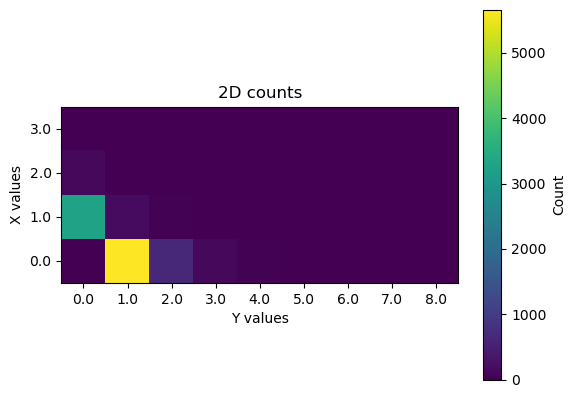

In [254]:
x_vals, y_vals = np.unique(x), np.unique(y)
count_matrix = np.zeros((len(x_vals), len(y_vals)), dtype=int)

for xi, yi in zip(x, y):
    count_matrix[np.where(x_vals == xi)[0][0],
                 np.where(y_vals == yi)[0][0]] += 1

plt.imshow(count_matrix, origin="lower")
plt.colorbar(label="Count")
plt.xticks(range(len(y_vals)), y_vals)
plt.yticks(range(len(x_vals)), x_vals)
plt.xlabel("Y values")
plt.ylabel("X values")
plt.title("2D counts")
plt.show()

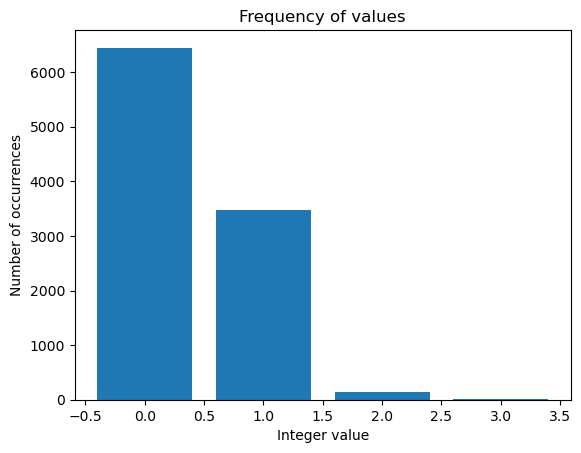

In [250]:



values, counts = np.unique(arr, return_counts=True)

plt.bar(values, counts)
plt.xlabel("Integer value")
plt.ylabel("Number of occurrences")
plt.title("Frequency of values")
plt.show()

In [230]:
print(np.mean(cos_sim))

0.99848074


In [180]:
len(masks_enc[0][0]) # -> 513

1127

In [181]:
len(masks_pred[0][0]) # -> 769

1691

In [189]:
masks_pred[0][0]

tensor([   0, 1299, 1026, 2136, 2502, 2537, 1552,  982,  949, 1328,  223, 1702,
         494, 2033, 2133,  703,  786, 2412, 1465,  654, 1936,  650, 2810,  408,
        2518, 1327,  464,  715, 2380,  393,  378, 1031, 2041, 1367, 1252, 1988,
         245,  362, 2438,  453, 1965,  991,  967, 2214,  162,  122,  596, 1758,
        1421,   11, 2781,  598,   36,  726, 1140,  588, 2056, 1812,  951,  859,
        2000, 1224, 2300, 1158,  460,  779,  473,  419, 2555, 2629,  924, 2578,
        2394,  841, 2369,  711, 1803, 1523,  177,  774,  866, 2516, 1077,  376,
        1858, 2381,  742, 1506, 1235,  205,  503,  476,  785,  511,   95,   99,
         227,  241,   79,  222,  792,  760, 1267, 1049, 1393, 1867, 1919,  629,
        1216,  794,  927, 1431, 1605,   22, 1756, 1621, 2545, 1053,  939, 1325,
        2299, 1917, 1498, 2089, 2319, 2459, 1607, 2144, 2079,  871, 2105, 2132,
        1656, 1078,  267, 2643,  624,  522,  931, 2585,   37, 2356,  745, 1289,
        1581, 1144,  803,  881,  750, 15

In [185]:
513 + 769

1282

In [182]:
len(masks_enc[0][0]) + len(masks_pred[0][0])

2818

In [148]:
max(masks_enc[0][0])

tensor(1274)

In [149]:
max(masks_pred[0][0])

tensor(1280)

In [184]:
k = 11
256 * k

2816

In [59]:
masks_attention

tensor([[[[False,  True,  True,  True,  True,  True,  True,  True,  True,  True,
            True,  True,  True,  True,  True,  True,  True,  True,  True,  True,
            True,  True,  True,  True,  True,  True,  True,  True,  True,  True,
            True,  True,  True,  True,  True,  True,  True,  True,  True,  True,
            True,  True,  True,  True,  True,  True,  True,  True,  True,  True,
            True,  True,  True,  True,  True,  True,  True,  True,  True,  True,
            True,  True,  True,  True,  True,  True,  True,  True,  True,  True,
            True,  True,  True,  True,  True,  True,  True,  True,  True,  True,
            True,  True,  True,  True,  True,  True,  True,  True,  True,  True,
            True,  True,  True,  True,  True,  True,  True,  True,  True,  True,
            True,  True,  True,  True,  True,  True,  True,  True,  True,  True,
            True,  True,  True,  True,  True,  True,  True,  True,  True,  True,
            True,  True,  Tr

In [ ]:
udata

In [ ]:
(udata['tokens'][0] != 0).sum()

In [ ]:
(udata['values'][0] != 0).sum()

In [ ]:
(udata['rel_x_coords'][0] != 0).sum()

In [ ]:
import math
distances = [math.sqrt(dx**2 + dy**2) for dx, dy in zip(udata['rel_x_coords'][0], udata['rel_y_coords'][0])]

In [ ]:
udata['segments'][0][513:1800]

In [ ]:
udata['rel_x_coords'][0][:513]

In [ ]:
distances

In [ ]:
(udata['positions'][0] != 0).sum()

In [ ]:
(udata['segments'][0] != 0).sum()

In [ ]:
(udata['tokens'][1] != 0).sum()

In [ ]:
(udata['tokens'][2] != 0).sum()

In [ ]:
(udata['tokens'][30] != 0).sum()

In [ ]:
udata['tokens'].shape

In [ ]:
masks_attention[2].sum()

In [ ]:
idx_temp = [79009928, 61334070, 61012720, 59885839, 51564208, 51071983, 50578755, 51490262, 21762874, 50991337, 20596439, 49076277, 55395062, 50791923, 51597330]

In [ ]:
dataset_tmp = train_dataset.select(idx_temp)

In [ ]:
len(sampler.lengths)

In [ ]:
dataset_tmp['n_nonzero_tokens']

In [ ]:
g = torch.Generator()
g.manual_seed(0)
indices = sampler._get_length_grouped_indices(generator=g)

In [ ]:
indices[:100]

In [ ]:
train_dataset

In [ ]:
ordered_dataset = train_dataset.select(indices[-100:])

In [ ]:
train_dataset[79009928]['n_nonzero_tokens']

In [ ]:
list(ordered_dataset['n_nonzero_tokens'])

In [ ]:
print(torch.count_nonzero(cell_dataset[79009928]['tokens']))
print(torch.count_nonzero(cell_dataset[61334070]['tokens']))
print(torch.count_nonzero(cell_dataset[61012720]['tokens']))
print(torch.count_nonzero(cell_dataset[59885839]['tokens']))
print(torch.count_nonzero(cell_dataset[51564208]['tokens']))
print(torch.count_nonzero(cell_dataset[51071983]['tokens']))
print(torch.count_nonzero(cell_dataset[50578755]['tokens']))
print(torch.count_nonzero(cell_dataset[51490262]['tokens']))

In [ ]:
with open('/lustre/scratch126/cellgen/lotfollahi/DATASETS/tokenizer/hst_corpus_90m_32_None_None_None_None_None_shifted_log_knn_10_precomputed_loader_idx.pkl', "wb") as f: 
    pickle.dump(indices, f)

In [ ]:
with open('/lustre/scratch126/cellgen/lotfollahi/DATASETS/tokenizer/hst_corpus_90m_32_None_None_None_None_None_shifted_log_knn_10_precomputed_loader_idx.pkl', "rb") as f: 
    indices2 = pickle.load(f)

In [ ]:
indices[:100]

In [ ]:
indices2[:100]

In [ ]:
test = torch.tensor([0, 0, 0, 1, 1, 1, 2, 2, 2])

In [ ]:
mask = test == 1

In [ ]:
mask

In [ ]:
torch.nonzero(mask, as_tuple=True)[0]

In [ ]:
import numpy as np
import scanpy as sc

from nichejepa.preprocessors.graph import construct_neighbor_graph

In [ ]:
adata_neigh = sc.read_h5ad('/nfs/team361/sb75/DATASETS/silver/xhe1008-1-20b_1p/section020_SOB26.h5ad')

In [ ]:
n_neighs = 10
radius = None
delaunay = None

In [ ]:
print('Computing spatial neighborhood...')
# Construct neighbor graph
adata_neigh = construct_neighbor_graph(
    adata_neigh,
    n_neighs=n_neighs,
    radius=radius,
    delaunay=delaunay,
    include_self_loop=False,
    compute_neighbor_counts=False)

In [ ]:
adata_neigh.obsp['spatial_connectivities'][0].indices

In [ ]:
adata_neigh.obsp['spatial_connectivities'][0].nonzero()[1]

In [ ]:
adata_neigh.obsp['spatial_distances'].indptr[2]

In [ ]:
adata_neigh.obsp['spatial_distances'].indptr[3]

In [ ]:
cell_start = adata_neigh.obsp['spatial_distances'].indptr[0]
cell_end = adata_neigh.obsp['spatial_distances'].indptr[0+1]
cell_distances = adata_neigh.obsp[
    'spatial_distances'].data[cell_start:cell_end]
cell_distances

In [ ]:
rel_x_coord = []
rel_y_coord = []

neighbor_indices = adata_neigh.obsp[
    'spatial_connectivities'][0].indices
for j in neighbor_indices:
    rel_x_coord.extend([(
        adata_neigh.obsm['spatial'][j, 0] - adata_neigh.obsm['spatial'][0, 0]
        ).tolist()])
    rel_y_coord.extend([(
        adata_neigh.obsm['spatial'][j, 1] - adata_neigh.obsm['spatial'][0, 1]
        ).tolist()])

print(rel_x_coord)
print(rel_y_coord)

In [ ]:
-7-(-10)

In [ ]:
np.sqrt(5.62371826171875**2 + 10.005859375 **2)

In [ ]:
np.sqrt(rel_x_coord**2 + rel_y_coord**2)

In [ ]:
adata_neigh